In [29]:
# B5 - Integrasi Rangkaian Praproses
# NIM: 233051007
# SEED: 1007

from pathlib import Path
import sys
import os
import json
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Lokasi proyek
ROOT = Path("/content/drive/MyDrive/simuteh")
SRC = ROOT / "src"
DATA = ROOT / "data" / "sintetis"
HASIL = ROOT / "hasil"

# Hubungkan Google Drive jika belum terhubung
if not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")

# Pastikan folder hasil tersedia
HASIL.mkdir(parents=True, exist_ok=True)

# Hubungkan modul praproses
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

if not (SRC / "praproses.py").exists():
    raise FileNotFoundError(
        f"Modul tidak ditemukan: {SRC / 'praproses.py'}"
    )

from praproses import praproses

print("Lingkungan B5 berhasil disiapkan.")
print("Folder proyek :", ROOT)
print("Folder sumber :", SRC)
print("Folder dataset:", DATA)
print("Folder hasil  :", HASIL)
print("Modul praproses berhasil diimpor.")


Lingkungan B5 berhasil disiapkan.
Folder proyek : /content/drive/MyDrive/simuteh
Folder sumber : /content/drive/MyDrive/simuteh/src
Folder dataset: /content/drive/MyDrive/simuteh/data/sintetis
Folder hasil  : /content/drive/MyDrive/simuteh/hasil
Modul praproses berhasil diimpor.


In [30]:
# B5 - Sel 2: Pemeriksaan Dataset

folder_citra = DATA / "citra"
folder_bersih = DATA / "bersih"
folder_mask_daun = DATA / "mask_daun"
folder_mask_bercak = DATA / "mask_bercak"

folder_dataset = {
    "Citra input": folder_citra,
    "Citra bersih": folder_bersih,
    "Mask daun": folder_mask_daun,
    "Mask bercak": folder_mask_bercak
}

for nama, folder in folder_dataset.items():
    if not folder.exists():
        raise FileNotFoundError(f"Folder {nama} tidak ditemukan: {folder}")

    jumlah = sum(
        1 for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in
        {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
    )

    print(f"{nama}: {jumlah} file")

daftar_citra = sorted(
    p for p in folder_citra.iterdir()
    if p.is_file() and p.suffix.lower() in
    {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
)

if len(daftar_citra) == 0:
    raise RuntimeError("Dataset citra kosong.")

print("\nContoh file:", daftar_citra[0].name)

contoh = cv2.imread(str(daftar_citra[0]))

if contoh is None:
    raise RuntimeError("Citra contoh gagal dibaca.")

print("Ukuran citra:", contoh.shape)
print("Tipe data:", contoh.dtype)
print("\nPemeriksaan dataset selesai.")


Citra input: 60 file
Citra bersih: 60 file
Mask daun: 60 file
Mask bercak: 60 file

Contoh file: teh_001.png
Ukuran citra: (480, 640, 3)
Tipe data: uint8

Pemeriksaan dataset selesai.


In [31]:
# B5 - Sel 3: Konfigurasi Praproses

konfigurasi = {
    "CLAHE_Median5": {
        "kanal": "Grayscale",
        "metode_perbaikan": "CLAHE",
        "clahe_clip_limit": 2.0,
        "clahe_tile_grid_size": [8, 8],
        "metode_penapisan": "median",
        "median_kernel": 5
    },
    "Equalize_Median5": {
        "kanal": "Grayscale",
        "metode_perbaikan": "equalize",
        "clahe_clip_limit": 2.0,
        "clahe_tile_grid_size": [8, 8],
        "metode_penapisan": "median",
        "median_kernel": 5
    },
    "CLAHE_Median3": {
        "kanal": "Grayscale",
        "metode_perbaikan": "CLAHE",
        "clahe_clip_limit": 2.0,
        "clahe_tile_grid_size": [8, 8],
        "metode_penapisan": "median",
        "median_kernel": 3
    }
}

for nama, parameter in konfigurasi.items():
    print(f"\n{nama}")
    print(json.dumps(parameter, indent=2))

print("\nJumlah konfigurasi:", len(konfigurasi))


CLAHE_Median5
{
  "kanal": "Grayscale",
  "metode_perbaikan": "CLAHE",
  "clahe_clip_limit": 2.0,
  "clahe_tile_grid_size": [
    8,
    8
  ],
  "metode_penapisan": "median",
  "median_kernel": 5
}

Equalize_Median5
{
  "kanal": "Grayscale",
  "metode_perbaikan": "equalize",
  "clahe_clip_limit": 2.0,
  "clahe_tile_grid_size": [
    8,
    8
  ],
  "metode_penapisan": "median",
  "median_kernel": 5
}

CLAHE_Median3
{
  "kanal": "Grayscale",
  "metode_perbaikan": "CLAHE",
  "clahe_clip_limit": 2.0,
  "clahe_tile_grid_size": [
    8,
    8
  ],
  "metode_penapisan": "median",
  "median_kernel": 3
}

Jumlah konfigurasi: 3


In [32]:
# B5 - Sel 4: Uji Integrasi Pipeline

citra_uji = cv2.imread(str(daftar_citra[0]))

hasil_uji = {}

for nama, parameter in konfigurasi.items():
    mulai = time.perf_counter()

    keluaran = praproses(
        citra_uji.copy(),
        p=parameter.copy()
    )

    waktu_ms = (time.perf_counter() - mulai) * 1000

    hasil_akhir = keluaran

    if hasil_akhir is None:
        raise RuntimeError(f"Hasil kosong pada konfigurasi {nama}")

    hasil_uji[nama] = {
        "hasil": hasil_akhir,
        "waktu_ms": waktu_ms
    }

    print(f"\nKonfigurasi: {nama}")
    print("Ukuran hasil:", hasil_akhir.shape)
    print("Tipe data:", hasil_akhir.dtype)
    print(f"Waktu proses: {waktu_ms:.3f} ms")

print("\nUji integrasi pipeline berhasil.")


Konfigurasi: CLAHE_Median5
Ukuran hasil: (480, 640, 3)
Tipe data: uint8
Waktu proses: 8.296 ms

Konfigurasi: Equalize_Median5
Ukuran hasil: (480, 640, 3)
Tipe data: uint8
Waktu proses: 7.916 ms

Konfigurasi: CLAHE_Median3
Ukuran hasil: (480, 640, 3)
Tipe data: uint8
Waktu proses: 8.298 ms

Uji integrasi pipeline berhasil.


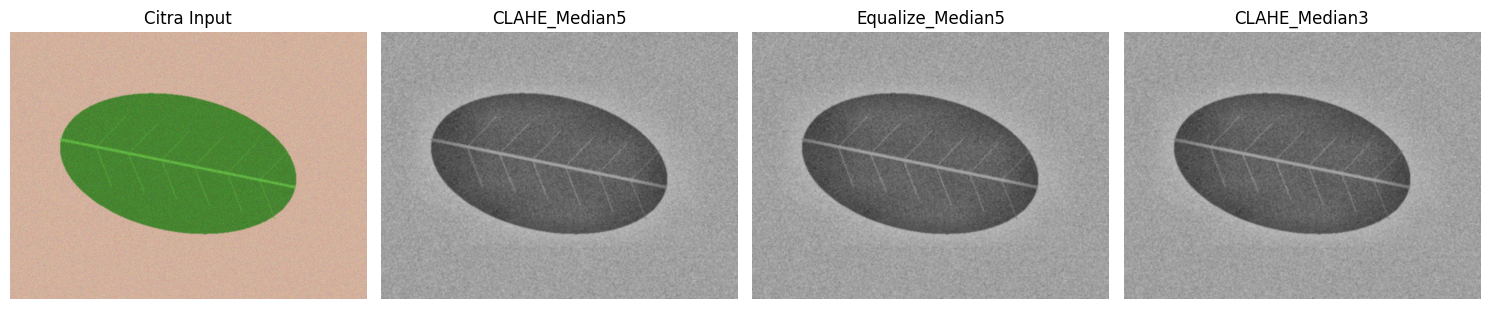

Visualisasi berhasil disimpan.


In [33]:
# B5 - Sel 5: Visualisasi Perbandingan

citra_rgb = cv2.cvtColor(citra_uji, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.imshow(citra_rgb)
plt.title("Citra Input")
plt.axis("off")

for i, (nama, data_hasil) in enumerate(hasil_uji.items(), start=2):
    hasil = data_hasil["hasil"]

    if hasil.ndim == 3:
        hasil = cv2.cvtColor(hasil, cv2.COLOR_BGR2GRAY)

    plt.subplot(1, 4, i)
    plt.imshow(hasil, cmap="gray", vmin=0, vmax=255)
    plt.title(nama)
    plt.axis("off")

plt.tight_layout()

plt.savefig(
    HASIL / "b5_visualisasi_perbandingan.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Visualisasi berhasil disimpan.")


In [34]:
# B5 - Sel 6: Evaluasi PSNR

def hitung_psnr(referensi, hasil):
    referensi = referensi.astype(np.float64)
    hasil = hasil.astype(np.float64)

    mse = np.mean((referensi - hasil) ** 2)

    if mse == 0:
        return float("inf")

    return float(10 * np.log10((255 ** 2) / mse))


path_referensi = folder_bersih / daftar_citra[0].name

if not path_referensi.exists():
    kandidat = list(folder_bersih.glob(daftar_citra[0].stem + ".*"))
    if not kandidat:
        raise FileNotFoundError(
            f"Referensi bersih untuk {daftar_citra[0].name} tidak ditemukan."
        )
    path_referensi = kandidat[0]

referensi = cv2.imread(
    str(path_referensi),
    cv2.IMREAD_GRAYSCALE
)

if referensi is None:
    raise RuntimeError("Citra referensi bersih gagal dibaca.")

hasil_evaluasi_contoh = []

for nama, data_hasil in hasil_uji.items():
    hasil = data_hasil["hasil"]

    if hasil.ndim == 3:
        hasil = cv2.cvtColor(hasil, cv2.COLOR_BGR2GRAY)

    if hasil.shape != referensi.shape:
        raise ValueError(
            f"Ukuran hasil dan referensi tidak sama untuk {nama}"
        )

    hasil_evaluasi_contoh.append({
        "Konfigurasi": nama,
        "PSNR_dB": hitung_psnr(referensi, hasil),
        "Rerata_intensitas": float(hasil.mean()),
        "Simpangan_baku": float(hasil.std()),
        "Waktu_ms": data_hasil["waktu_ms"]
    })

df_contoh = pd.DataFrame(hasil_evaluasi_contoh)

display(df_contoh.round(3))

df_contoh.to_csv(
    HASIL / "b5_evaluasi_contoh.csv",
    index=False
)

print("Evaluasi satu citra selesai.")

,Konfigurasi,PSNR_dB,Rerata_intensitas,Simpangan_baku,Waktu_ms
0,CLAHE_Median5,21.194,144.213,31.695,8.296
1,Equalize_Median5,21.194,144.213,31.695,7.916
2,CLAHE_Median3,21.194,144.213,31.695,8.298


Evaluasi satu citra selesai.


In [35]:
# B5 - Sel 7: Evaluasi Seluruh Dataset

def cari_file_pasangan(folder, nama_dasar):
    kandidat = sorted(
        p for p in folder.iterdir()
        if p.is_file() and p.stem == nama_dasar
    )
    return kandidat[0] if kandidat else None


def evaluasi_kontras(gray, mask_daun, mask_bercak):
    daun = mask_daun > 0
    bercak = (mask_bercak > 0) & daun
    sehat = daun & (mask_bercak == 0)

    if not bercak.any() or not sehat.any():
        return np.nan

    nilai_bercak = gray[bercak].astype(np.float64)
    nilai_sehat = gray[sehat].astype(np.float64)

    return float(
        abs(nilai_bercak.mean() - nilai_sehat.mean())
        / (nilai_sehat.std() + 1e-6)
    )


hasil_seluruh = []
jumlah_dilewati = 0

for path_citra in daftar_citra:
    nama = path_citra.stem

    path_bersih = cari_file_pasangan(folder_bersih, nama)
    path_daun = cari_file_pasangan(folder_mask_daun, nama)
    path_bercak = cari_file_pasangan(folder_mask_bercak, nama)

    if not all([path_bersih, path_daun, path_bercak]):
        print("Pasangan tidak lengkap, dilewati:", nama)
        jumlah_dilewati += 1
        continue

    citra = cv2.imread(str(path_citra))
    bersih = cv2.imread(str(path_bersih), cv2.IMREAD_GRAYSCALE)
    mask_daun = cv2.imread(str(path_daun), cv2.IMREAD_GRAYSCALE)
    mask_bercak = cv2.imread(str(path_bercak), cv2.IMREAD_GRAYSCALE)

    if any(x is None for x in [citra, bersih, mask_daun, mask_bercak]):
        print("File gagal dibaca, dilewati:", nama)
        jumlah_dilewati += 1
        continue

    if any(
        x.shape[:2] != citra.shape[:2]
        for x in [bersih, mask_daun, mask_bercak]
    ):
        print("Ukuran tidak sama, dilewati:", nama)
        jumlah_dilewati += 1
        continue

    for nama_konfigurasi, parameter in konfigurasi.items():
        mulai = time.perf_counter()

        keluaran = praproses(
            citra.copy(),
            p=parameter.copy()
        )

        waktu_ms = (time.perf_counter() - mulai) * 1000
        hasil = keluaran

        if hasil.ndim == 3:
            hasil = cv2.cvtColor(hasil, cv2.COLOR_BGR2GRAY)

        hasil_seluruh.append({
            "nama_citra": nama,
            "konfigurasi": nama_konfigurasi,
            "PSNR_dB": hitung_psnr(bersih, hasil),
            "kontras_bercak": evaluasi_kontras(
                hasil, mask_daun, mask_bercak
            ),
            "waktu_ms": waktu_ms
        })

df_detail = pd.DataFrame(hasil_seluruh)

if df_detail.empty:
    raise RuntimeError(
        "Tidak ada citra yang berhasil dievaluasi. "
        "Periksa pasangan file dan nama dataset."
    )

df_detail.to_csv(
    HASIL / "b5_evaluasi_detail.csv",
    index=False
)

print("Jumlah citra berhasil dievaluasi:",
      df_detail["nama_citra"].nunique())
print("Jumlah citra dilewati:", jumlah_dilewati)
print("Jumlah baris evaluasi:", len(df_detail))

display(df_detail.head())

Jumlah citra berhasil dievaluasi: 60
Jumlah citra dilewati: 0
Jumlah baris evaluasi: 180


,nama_citra,konfigurasi,PSNR_dB,kontras_bercak,waktu_ms
0,teh_001,CLAHE_Median5,21.193682,NaN,7.895856
1,teh_001,Equalize_Median5,21.193682,NaN,6.477727
2,teh_001,CLAHE_Median3,21.193682,NaN,7.090683
3,teh_002,CLAHE_Median5,13.731595,NaN,7.868923
4,teh_002,Equalize_Median5,13.731595,NaN,6.487003


In [36]:
# B5 - Sel 8: Ringkasan Hasil Evaluasi

ringkasan = (
    df_detail.groupby("konfigurasi")
    .agg(
        jumlah_citra=("nama_citra", "nunique"),
        PSNR_rerata_dB=("PSNR_dB", "mean"),
        kontras_bercak_rerata=("kontras_bercak", "mean"),
        waktu_rerata_ms=("waktu_ms", "mean")
    )
    .reset_index()
)

ringkasan.to_csv(
    HASIL / "b5_ringkasan_konfigurasi.csv",
    index=False
)

display(ringkasan.round(3))

,konfigurasi,jumlah_citra,PSNR_rerata_dB,kontras_bercak_rerata,waktu_rerata_ms
0,CLAHE_Median3,60,17.564,2.495,5.958
1,CLAHE_Median5,60,17.564,2.495,6.102
2,Equalize_Median5,60,17.564,2.495,6.018


In [37]:
# B5 - Sel 9: Pemilihan Parameter Akhir

ringkasan_valid = ringkasan.dropna(subset=["PSNR_rerata_dB"])

if ringkasan_valid.empty:
    raise RuntimeError("Tidak ada nilai PSNR yang dapat digunakan.")

terpilih = ringkasan_valid.sort_values(
    "PSNR_rerata_dB",
    ascending=False
).iloc[0]

nama_terpilih = terpilih["konfigurasi"]
parameter_akhir = konfigurasi[nama_terpilih].copy()

data_parameter = {
    "nim": "233051007",
    "seed": 1007,
    "konfigurasi_terpilih": nama_terpilih,
    "parameter": parameter_akhir,
    "dasar_pemilihan": (
        "Konfigurasi dengan PSNR rata-rata tertinggi terhadap "
        "citra referensi bersih di antara konfigurasi yang diuji. "
        "Kontras bercak dan waktu proses juga diperiksa."
    ),
    "hasil_ringkasan": {
        k: (
            float(v)
            if isinstance(v, (np.floating, float, np.integer, int))
            else str(v)
        )
        for k, v in terpilih.to_dict().items()
    }
}

with open(
    HASIL / "param_praproses.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(data_parameter, f, indent=2, ensure_ascii=False)

print("Konfigurasi terpilih:", nama_terpilih)
print("\nParameter akhir:")
print(json.dumps(parameter_akhir, indent=2))
print("\nFile tersimpan:", HASIL / "param_praproses.json")

Konfigurasi terpilih: CLAHE_Median3

Parameter akhir:
{
  "kanal": "Grayscale",
  "metode_perbaikan": "CLAHE",
  "clahe_clip_limit": 2.0,
  "clahe_tile_grid_size": [
    8,
    8
  ],
  "metode_penapisan": "median",
  "median_kernel": 3
}

File tersimpan: /content/drive/MyDrive/simuteh/hasil/param_praproses.json


In [38]:
# B5 - Sel 11: Ringkasan untuk Laporan

baris_terpilih = ringkasan_valid.sort_values(
    "PSNR_rerata_dB",
    ascending=False
).iloc[0]

kesimpulan = f"""
B5: INTEGRASI RANGKAIAN PRAPROSES
NIM: 233051007
SEED: 1007

Pengujian membandingkan {len(konfigurasi)} konfigurasi praproses
pada {df_detail['nama_citra'].nunique()} citra yang berhasil diproses.

Konfigurasi dengan PSNR rata-rata tertinggi adalah:
{baris_terpilih['konfigurasi']}

PSNR rata-rata:
{baris_terpilih['PSNR_rerata_dB']:.3f} dB

Kontras bercak rata-rata:
{baris_terpilih['kontras_bercak_rerata']:.3f}

Waktu proses rata-rata:
{baris_terpilih['waktu_rerata_ms']:.3f} ms

Interpretasi:
PSNR menunjukkan kemiripan hasil praproses terhadap citra referensi
bersih. Kontras bercak digunakan untuk mengamati perbedaan intensitas
antara area bercak dan area daun sehat. Waktu proses digunakan untuk
membandingkan biaya komputasi setiap konfigurasi.

Konfigurasi dengan PSNR tertinggi belum tentu paling baik untuk
semua tujuan. Pemilihan parameter akhir perlu mempertimbangkan
PSNR, kontras bercak, waktu proses, dan kebutuhan analisis citra.
"""

with open(
    HASIL / "b5_ringkasan.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(kesimpulan)

print(kesimpulan)


B5: INTEGRASI RANGKAIAN PRAPROSES
NIM: 233051007
SEED: 1007

Pengujian membandingkan 3 konfigurasi praproses
pada 60 citra yang berhasil diproses.

Konfigurasi dengan PSNR rata-rata tertinggi adalah:
CLAHE_Median3

PSNR rata-rata:
17.564 dB

Kontras bercak rata-rata:
2.495

Waktu proses rata-rata:
5.958 ms

Interpretasi:
PSNR menunjukkan kemiripan hasil praproses terhadap citra referensi
bersih. Kontras bercak digunakan untuk mengamati perbedaan intensitas
antara area bercak dan area daun sehat. Waktu proses digunakan untuk
membandingkan biaya komputasi setiap konfigurasi.

Konfigurasi dengan PSNR tertinggi belum tentu paling baik untuk
semua tujuan. Pemilihan parameter akhir perlu mempertimbangkan
PSNR, kontras bercak, waktu proses, dan kebutuhan analisis citra.



In [39]:
# B5 - Sel 12: Pemeriksaan Akhir

file_wajib = [
    HASIL / "b5_evaluasi_detail.csv",
    HASIL / "b5_ringkasan_konfigurasi.csv",
    HASIL / "param_praproses.json",
    HASIL / "b5_perbandingan_psnr.png",
    HASIL / "b5_perbandingan_kontras_bercak.png",
    HASIL / "b5_perbandingan_waktu.png",
    HASIL / "b5_ringkasan.txt"
]

print("DAFTAR FILE HASIL B5")
print("=" * 45)

semua_ada = True

for file in file_wajib:
    status = "OK" if file.exists() else "BELUM ADA"
    print(f"{status}: {file.name}")

    if not file.exists():
        semua_ada = False

if semua_ada:
    print("\nSemua file keluaran utama B5 tersedia.")
else:
    print("\nMasih ada file yang belum dibuat. Periksa sel sebelumnya.")

DAFTAR FILE HASIL B5
OK: b5_evaluasi_detail.csv
OK: b5_ringkasan_konfigurasi.csv
OK: param_praproses.json
OK: b5_perbandingan_psnr.png
OK: b5_perbandingan_kontras_bercak.png
OK: b5_perbandingan_waktu.png
OK: b5_ringkasan.txt

Semua file keluaran utama B5 tersedia.


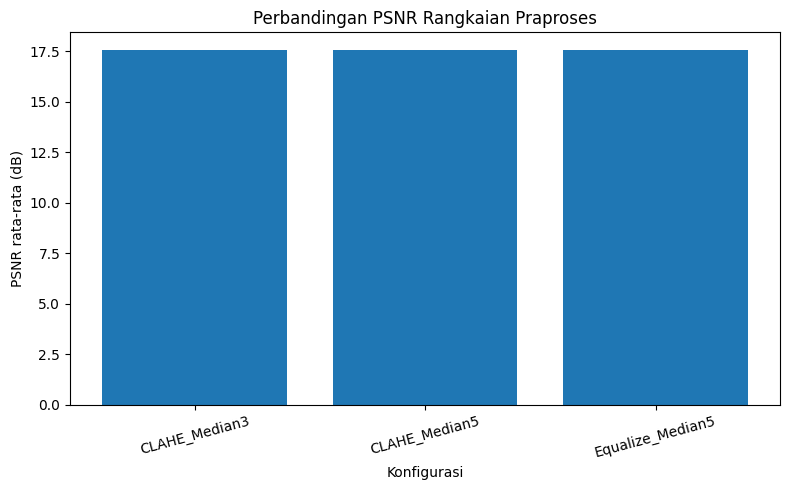

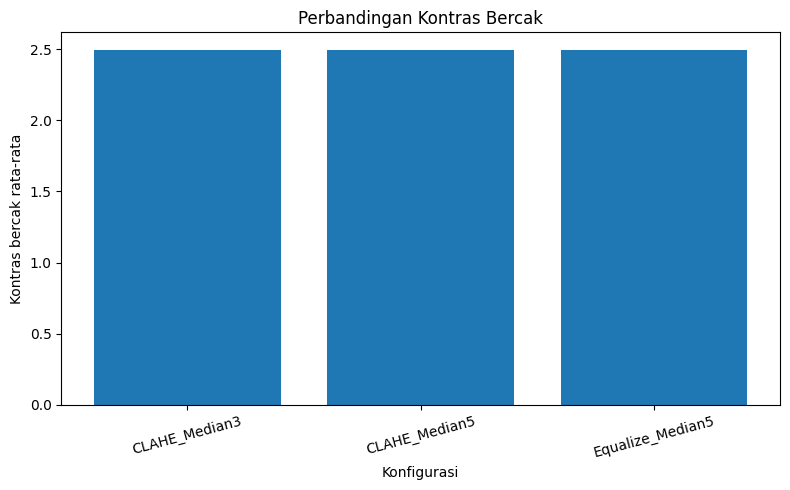

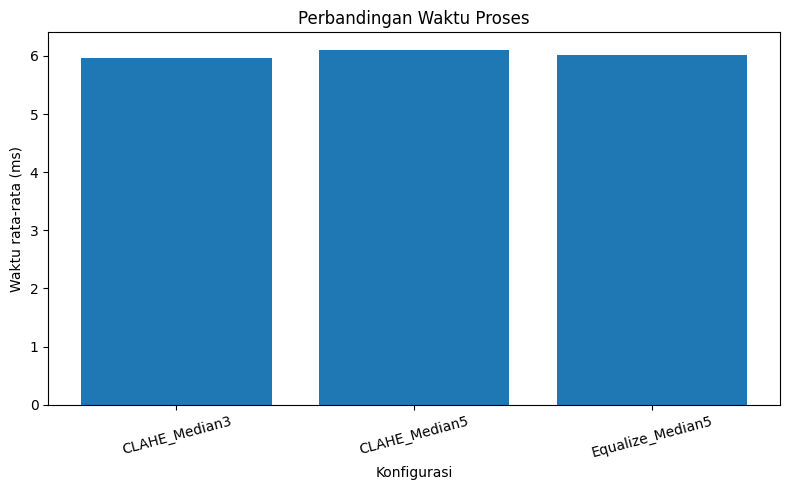


Pemeriksaan file grafik:
OK: b5_perbandingan_psnr.png
OK: b5_perbandingan_kontras_bercak.png
OK: b5_perbandingan_waktu.png


In [40]:
# B5 - Perbaikan: Membuat dan Menyimpan Grafik

# Pastikan folder hasil tersedia
HASIL.mkdir(parents=True, exist_ok=True)

# 1. Grafik PSNR
plt.figure(figsize=(8, 5))
plt.bar(
    ringkasan["konfigurasi"],
    ringkasan["PSNR_rerata_dB"]
)
plt.title("Perbandingan PSNR Rangkaian Praproses")
plt.xlabel("Konfigurasi")
plt.ylabel("PSNR rata-rata (dB)")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    str(HASIL / "b5_perbandingan_psnr.png"),
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()

# 2. Grafik Kontras Bercak
plt.figure(figsize=(8, 5))
plt.bar(
    ringkasan["konfigurasi"],
    ringkasan["kontras_bercak_rerata"]
)
plt.title("Perbandingan Kontras Bercak")
plt.xlabel("Konfigurasi")
plt.ylabel("Kontras bercak rata-rata")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    str(HASIL / "b5_perbandingan_kontras_bercak.png"),
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()

# 3. Grafik Waktu Proses
plt.figure(figsize=(8, 5))
plt.bar(
    ringkasan["konfigurasi"],
    ringkasan["waktu_rerata_ms"]
)
plt.title("Perbandingan Waktu Proses")
plt.xlabel("Konfigurasi")
plt.ylabel("Waktu rata-rata (ms)")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    str(HASIL / "b5_perbandingan_waktu.png"),
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()

# 4. Verifikasi hasil penyimpanan
print("\nPemeriksaan file grafik:")

file_grafik = [
    "b5_perbandingan_psnr.png",
    "b5_perbandingan_kontras_bercak.png",
    "b5_perbandingan_waktu.png"
]

for nama in file_grafik:
    path = HASIL / nama
    print(
        f"{'OK' if path.exists() and path.stat().st_size > 0 else 'GAGAL'}: "
        f"{nama}"
    )

In [41]:
# B5 - Perbaikan modul sesuai petunjuk praktikum

kode_praproses = r'''
"""praproses.py: rangkaian praproses SIMUTEH."""

import json
from pathlib import Path

import cv2
import numpy as np


PARAM_BAWAAN = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,
}


def praproses(img_bgr, p=None):
    """Urutan: ubah ukuran, gamma, CLAHE kanal V,
    redam derau, lalu penajaman opsional.
    """
    if img_bgr is None:
        raise ValueError("Citra input tidak boleh kosong.")

    p = {**PARAM_BAWAAN, **(p or {})}

    # 1. Ubah ukuran dengan rasio aspek tetap.
    lebar = int(p["lebar"])
    if lebar <= 0:
        raise ValueError("Lebar citra harus lebih besar dari nol.")

    tinggi = max(1, round(img_bgr.shape[0] * lebar / img_bgr.shape[1]))

    img = cv2.resize(
        img_bgr,
        (lebar, tinggi),
        interpolation=cv2.INTER_AREA
    )

    # 2. Koreksi gamma.
    gamma = float(p["gamma"])
    if gamma <= 0:
        raise ValueError("Gamma harus lebih besar dari nol.")

    if gamma != 1.0:
        tabel = np.array(
            [((i / 255.0) ** (1.0 / gamma)) * 255
             for i in range(256)],
            dtype=np.uint8
        )
        img = cv2.LUT(img, tabel)

    # 3. CLAHE hanya pada kanal V dalam HSV.
    clip = float(p["clahe_clip"])
    if clip > 0:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        kanal_h, kanal_s, kanal_v = cv2.split(hsv)

        clahe = cv2.createCLAHE(
            clipLimit=clip,
            tileGridSize=(
                int(p["clahe_tile"]),
                int(p["clahe_tile"])
            )
        )

        kanal_v = clahe.apply(kanal_v)
        hsv = cv2.merge([kanal_h, kanal_s, kanal_v])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    # 4. Redam derau.
    metode = str(p["penapis"]).lower()
    kernel = int(p["kernel"])

    if metode != "none":
        if kernel < 1 or kernel % 2 == 0:
            raise ValueError("Kernel harus bilangan ganjil positif.")

        if metode == "median":
            img = cv2.medianBlur(img, kernel)

        elif metode == "rerata":
            img = cv2.blur(img, (kernel, kernel))

        elif metode == "gaussian":
            sigma = float(p["sigma"])
            img = cv2.GaussianBlur(
                img,
                (kernel, kernel),
                sigmaX=sigma
            )

        else:
            raise ValueError(f"Metode penapis tidak dikenal: {metode}")

    # 5. Penajaman opsional menggunakan unsharp masking.
    tajam_k = float(p["tajam_k"])

    if tajam_k > 0:
        blur = cv2.GaussianBlur(img, (0, 0), 1.0)
        img = cv2.addWeighted(
            img,
            1.0 + tajam_k,
            blur,
            -tajam_k,
            0
        )

    return img


def simpan_param(p, path=None):
    """Simpan parameter akhir dalam format JSON."""
    parameter = {**PARAM_BAWAAN, **(p or {})}

    if path is None:
        path = Path(__file__).resolve().parent.parent / "hasil" / "param_praproses.json"
    else:
        path = Path(path)

    path.parent.mkdir(parents=True, exist_ok=True)

    with open(path, "w", encoding="utf-8") as f:
        json.dump(parameter, f, indent=2, ensure_ascii=False)

    return str(path)
'''

path_modul = SRC / "praproses.py"
path_modul.write_text(kode_praproses, encoding="utf-8")

print("Modul diperbarui:", path_modul)
print("Sesuai struktur pipeline pada petunjuk praktikum.")

Modul diperbarui: /content/drive/MyDrive/simuteh/src/praproses.py
Sesuai struktur pipeline pada petunjuk praktikum.


In [42]:
# B5 - Uji modul baru

import importlib
import praproses as modul_praproses

importlib.reload(modul_praproses)

from praproses import praproses, simpan_param

citra_uji = cv2.imread(str(daftar_citra[0]))

parameter_uji = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0
}

hasil_uji_baru = praproses(citra_uji, parameter_uji)

print("Ukuran input :", citra_uji.shape)
print("Ukuran output:", hasil_uji_baru.shape)
print("Tipe output  :", hasil_uji_baru.dtype)

assert hasil_uji_baru is not None
assert hasil_uji_baru.shape[1] == 640
assert hasil_uji_baru.dtype == np.uint8

print("\nUji modul berhasil.")

Ukuran input : (480, 640, 3)
Ukuran output: (480, 640, 3)
Tipe output  : uint8

Uji modul berhasil.


In [43]:
kode_praproses = r'''
"""praproses.py: rangkaian praproses SIMUTEH."""
import json
from pathlib import Path
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,
}

def praproses(img_bgr, p=None):
    if img_bgr is None:
        raise ValueError("Citra input tidak boleh kosong.")

    p = {**PARAM_BAWAAN, **(p or {})}
    lebar = int(p["lebar"])

    if lebar <= 0:
        raise ValueError("Lebar citra harus lebih dari 0.")

    tinggi = max(1, round(img_bgr.shape[0] * lebar / img_bgr.shape[1]))
    img = cv2.resize(
        img_bgr, (lebar, tinggi),
        interpolation=cv2.INTER_AREA
    )

    gamma = float(p["gamma"])
    if gamma <= 0:
        raise ValueError("Gamma harus lebih dari 0.")

    if gamma != 1.0:
        tabel = np.array([
            ((i / 255.0) ** (1.0 / gamma)) * 255
            for i in range(256)
        ], dtype=np.uint8)
        img = cv2.LUT(img, tabel)

    clip = float(p["clahe_clip"])
    if clip > 0:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        kanal_h, kanal_s, kanal_v = cv2.split(hsv)

        clahe = cv2.createCLAHE(
            clipLimit=clip,
            tileGridSize=(
                int(p["clahe_tile"]),
                int(p["clahe_tile"])
            )
        )

        kanal_v = clahe.apply(kanal_v)
        hsv = cv2.merge([kanal_h, kanal_s, kanal_v])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    metode = str(p["penapis"]).lower()
    kernel = int(p["kernel"])

    if metode != "none":
        if kernel < 1 or kernel % 2 == 0:
            raise ValueError("Kernel harus berupa bilangan ganjil positif.")

        if metode == "median":
            img = cv2.medianBlur(img, kernel)
        elif metode == "rerata":
            img = cv2.blur(img, (kernel, kernel))
        elif metode == "gaussian":
            img = cv2.GaussianBlur(
                img, (kernel, kernel),
                sigmaX=float(p["sigma"])
            )
        else:
            raise ValueError("Metode penapis tidak dikenal.")

    tajam_k = float(p["tajam_k"])

    if tajam_k > 0:
        blur = cv2.GaussianBlur(img, (0, 0), 1.0)
        img = cv2.addWeighted(
            img, 1.0 + tajam_k,
            blur, -tajam_k, 0
        )

    return img


def simpan_param(p, path=None):
    parameter = {**PARAM_BAWAAN, **(p or {})}

    if path is None:
        path = (
            Path(__file__).resolve().parent.parent
            / "hasil" / "param_praproses.json"
        )
    else:
        path = Path(path)

    path.parent.mkdir(parents=True, exist_ok=True)

    with open(path, "w", encoding="utf-8") as f:
        json.dump(parameter, f, indent=2, ensure_ascii=False)

    return str(path)
'''

path_modul = SRC / "praproses.py"
path_modul.write_text(kode_praproses, encoding="utf-8")

print("Modul praproses.py berhasil diperbarui.")
print("Lokasi:", path_modul)

Modul praproses.py berhasil diperbarui.
Lokasi: /content/drive/MyDrive/simuteh/src/praproses.py


In [44]:
import importlib
import cv2
import numpy as np
import praproses as modul_praproses

importlib.reload(modul_praproses)

from praproses import praproses, simpan_param

citra_uji = cv2.imread(str(daftar_citra[0]))

parameter_uji = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0
}

hasil_uji_baru = praproses(citra_uji, parameter_uji)

print("Ukuran input :", citra_uji.shape)
print("Ukuran output:", hasil_uji_baru.shape)
print("Tipe output  :", hasil_uji_baru.dtype)

assert hasil_uji_baru is not None
assert hasil_uji_baru.shape[1] == 640
assert hasil_uji_baru.dtype == np.uint8

print("\nUji modul berhasil.")

Ukuran input : (480, 640, 3)
Ukuran output: (480, 640, 3)
Tipe output  : uint8

Uji modul berhasil.


In [45]:
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/simuteh")
DATA = ROOT / "data" / "sintetis"
HASIL = ROOT / "hasil"

HASIL.mkdir(parents=True, exist_ok=True)

# Cari file label dataset
kandidat_label = list(DATA.rglob("label.csv"))

print("File label ditemukan:")
for file in kandidat_label:
    print(file)

# Periksa struktur label
if kandidat_label:
    df_label = pd.read_csv(kandidat_label[0])

    print("\nKolom dataset:")
    print(df_label.columns.tolist())

    print("\nLima baris pertama:")
    display(df_label.head())

    print("\nJumlah data berdasarkan kelas:")
    print(df_label["kelas"].value_counts(dropna=False))

    print("\nJumlah data berdasarkan kondisi cahaya:")
    print(df_label["kondisi_cahaya"].value_counts(dropna=False))
else:
    print("File label.csv tidak ditemukan. Periksa lokasi dataset.")

File label ditemukan:
/content/drive/MyDrive/simuteh/data/sintetis/label.csv

Kolom dataset:
['nama_file', 'kelas', 'kondisi_cahaya', 'persen_bercak']

Lima baris pertama:


,nama_file,kelas,kondisi_cahaya,persen_bercak
0,teh_001.png,sehat,normal,0.0
1,teh_002.png,sehat,gelap,0.0
2,teh_003.png,sehat,terang,0.0
3,teh_004.png,sehat,kontras_rendah,0.0
4,teh_005.png,sehat,bayangan,0.0



Jumlah data berdasarkan kelas:
kelas
sehat     20
ringan    20
berat     20
Name: count, dtype: int64

Jumlah data berdasarkan kondisi cahaya:
kondisi_cahaya
normal            12
gelap             12
terang            12
kontras_rendah    12
bayangan          12
Name: count, dtype: int64


In [46]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

ROOT = Path("/content/drive/MyDrive/simuteh")
DATA = ROOT / "data" / "sintetis"
HASIL = ROOT / "hasil"

# Lokasi dataset
DIR_CITRA = DATA / "citra"
DIR_MASK_DAUN = DATA / "mask_daun"
DIR_MASK_BERCAK = DATA / "mask_bercak"

# Pastikan modul praproses tersedia
import importlib
import praproses as modul_praproses
importlib.reload(modul_praproses)

from praproses import praproses, simpan_param

# Parameter awal sesuai petunjuk praktikum
PARAM_B5 = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0
}

# Simpan parameter yang digunakan
file_param = simpan_param(
    PARAM_B5,
    HASIL / "param_praproses.json"
)

print("Parameter tersimpan:", file_param)

# Baca label dataset
df_label = pd.read_csv(DATA / "label.csv")

# Pilih 40 citra berbercak
df_bercak = df_label[df_label["kelas"].isin(["ringan", "berat"])].copy()

print("Jumlah citra berbercak:", len(df_bercak))

def cari_file(folder, nama):
    path = folder / nama
    if not path.exists():
        raise FileNotFoundError(f"File tidak ditemukan: {path}")
    return path

def hitung_kb(kanal, mask_daun, mask_bercak):
    daun = mask_daun > 0
    bercak = (mask_bercak > 0) & daun
    sehat = daun & ~(mask_bercak > 0)

    if not np.any(bercak) or not np.any(sehat):
        return np.nan

    nilai_bercak = kanal[bercak].astype(np.float64)
    nilai_sehat = kanal[sehat].astype(np.float64)

    return abs(nilai_bercak.mean() - nilai_sehat.mean()) / (
        nilai_sehat.std() + 1e-6
    )

hasil_evaluasi = []

for _, baris in df_bercak.iterrows():
    nama = baris["nama_file"]

    citra = cv2.imread(str(cari_file(DIR_CITRA, nama)))
    mask_daun = cv2.imread(
        str(cari_file(DIR_MASK_DAUN, nama)),
        cv2.IMREAD_GRAYSCALE
    )
    mask_bercak = cv2.imread(
        str(cari_file(DIR_MASK_BERCAK, nama)),
        cv2.IMREAD_GRAYSCALE
    )

    if citra is None or mask_daun is None or mask_bercak is None:
        raise ValueError(f"Gagal membaca citra atau mask: {nama}")

    # Gunakan kanal merah BGR sebagai kanal evaluasi awal.
    # Jika hasil B2 kamu menetapkan kanal lain, kita sesuaikan nanti.
    kanal_sebelum = citra[:, :, 2]

    citra_sesudah = praproses(citra, PARAM_B5)

    if mask_daun.shape != citra_sesudah.shape[:2]:
        mask_daun = cv2.resize(
            mask_daun,
            (citra_sesudah.shape[1], citra_sesudah.shape[0]),
            interpolation=cv2.INTER_NEAREST
        )

    if mask_bercak.shape != citra_sesudah.shape[:2]:
        mask_bercak = cv2.resize(
            mask_bercak,
            (citra_sesudah.shape[1], citra_sesudah.shape[0]),
            interpolation=cv2.INTER_NEAREST
        )

    kanal_sesudah = citra_sesudah[:, :, 2]

    kb_sebelum = hitung_kb(
        kanal_sebelum, mask_daun, mask_bercak
    )
    kb_sesudah = hitung_kb(
        kanal_sesudah, mask_daun, mask_bercak
    )

    if np.isfinite(kb_sebelum) and abs(kb_sebelum) > 1e-12:
        perubahan = (
            (kb_sesudah - kb_sebelum) / abs(kb_sebelum)
        ) * 100
    else:
        perubahan = np.nan

    hasil_evaluasi.append({
        "nama_file": nama,
        "kelas": baris["kelas"],
        "kondisi_cahaya": baris["kondisi_cahaya"],
        "KB_sebelum": kb_sebelum,
        "KB_sesudah": kb_sesudah,
        "perubahan_persen": perubahan
    })

df_evaluasi = pd.DataFrame(hasil_evaluasi)

# Simpan evaluasi per citra
file_detail = HASIL / "b5_evaluasi_40_citra.csv"
df_evaluasi.to_csv(file_detail, index=False)

# Ringkasan berdasarkan kondisi cahaya
ringkasan = (
    df_evaluasi.groupby("kondisi_cahaya", as_index=False)
    .agg(
        jumlah_citra=("nama_file", "count"),
        KB_sebelum=("KB_sebelum", "mean"),
        KB_sesudah=("KB_sesudah", "mean"),
        perubahan_persen=("perubahan_persen", "mean")
    )
)

ringkasan["catatan"] = ringkasan["perubahan_persen"].apply(
    lambda x: (
        "Kontras bercak meningkat"
        if x > 0.5 else
        "Kontras bercak menurun"
        if x < -0.5 else
        "Perubahan relatif kecil"
    )
)

file_ringkasan = HASIL / "b5_tabel12_kontras_bercak.csv"
ringkasan.to_csv(file_ringkasan, index=False)

print("\nTabel 12. Perbandingan KB Sebelum dan Sesudah Praproses")
display(ringkasan.round(4))

print("\nFile hasil disimpan:")
print(file_detail)
print(file_ringkasan)

Parameter tersimpan: /content/drive/MyDrive/simuteh/hasil/param_praproses.json
Jumlah citra berbercak: 40

Tabel 12. Perbandingan KB Sebelum dan Sesudah Praproses


,kondisi_cahaya,jumlah_citra,KB_sebelum,KB_sesudah,perubahan_persen,catatan
0,bayangan,8,4.1400,6.9838,71.0328,Kontras bercak meningkat
1,gelap,8,9.1146,15.1451,65.2692,Kontras bercak meningkat
2,kontras_rendah,8,3.8967,4.8514,28.2274,Kontras bercak meningkat
3,normal,8,10.1787,11.9018,17.5586,Kontras bercak meningkat
4,terang,8,7.5888,6.1711,-19.1831,Kontras bercak menurun



File hasil disimpan:
/content/drive/MyDrive/simuteh/hasil/b5_evaluasi_40_citra.csv
/content/drive/MyDrive/simuteh/hasil/b5_tabel12_kontras_bercak.csv


Jumlah citra sehat: 20

Evaluasi variasi intensitas pada daun sehat:


,kondisi_cahaya,jumlah_citra,std_sebelum,std_sesudah,perubahan_std_persen
0,bayangan,4,13.0960,9.5250,-26.4810
1,gelap,4,9.7038,6.9704,-27.6343
2,kontras_rendah,4,9.5763,9.8921,5.2863
3,normal,4,12.5694,10.1710,-18.6199
4,terang,4,11.4844,12.4167,10.6900


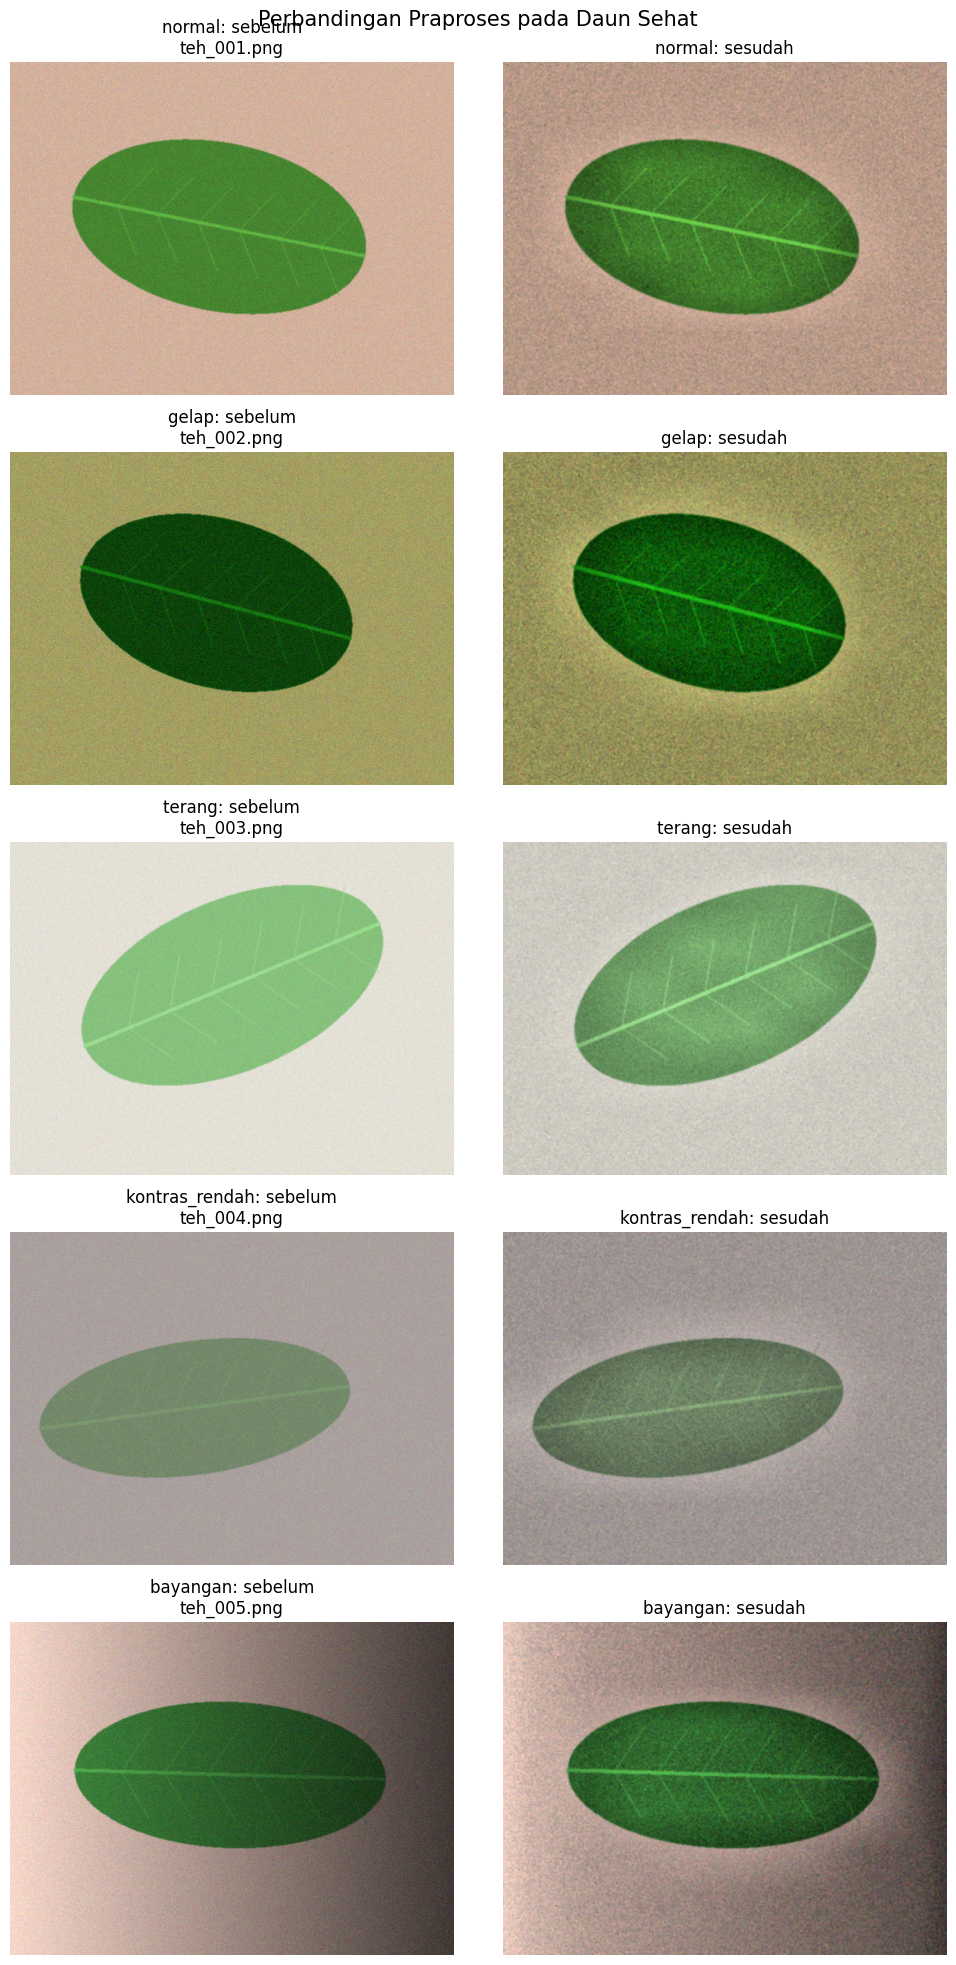


File tersimpan:
/content/drive/MyDrive/simuteh/hasil/b5_evaluasi_20_citra_sehat.csv
/content/drive/MyDrive/simuteh/hasil/b5_ringkasan_citra_sehat.csv
/content/drive/MyDrive/simuteh/hasil/b5_panel_citra_sehat.png


In [47]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

ROOT = Path("/content/drive/MyDrive/simuteh")
DATA = ROOT / "data" / "sintetis"
HASIL = ROOT / "hasil"

DIR_CITRA = DATA / "citra"
DIR_MASK_DAUN = DATA / "mask_daun"

df_label = pd.read_csv(DATA / "label.csv")
df_sehat = df_label[df_label["kelas"] == "sehat"].copy()

print("Jumlah citra sehat:", len(df_sehat))

hasil_sehat = []
contoh_per_kondisi = {}

for _, baris in df_sehat.iterrows():
    nama = baris["nama_file"]

    citra = cv2.imread(str(DIR_CITRA / nama))
    mask_daun = cv2.imread(
        str(DIR_MASK_DAUN / nama),
        cv2.IMREAD_GRAYSCALE
    )

    if citra is None or mask_daun is None:
        raise FileNotFoundError(f"Citra atau mask tidak ditemukan: {nama}")

    citra_sesudah = praproses(citra, PARAM_B5)

    # Sesuaikan mask jika ukuran citra berubah
    if mask_daun.shape != citra_sesudah.shape[:2]:
        mask_daun = cv2.resize(
            mask_daun,
            (citra_sesudah.shape[1], citra_sesudah.shape[0]),
            interpolation=cv2.INTER_NEAREST
        )

    # Gunakan kanal merah BGR agar konsisten dengan evaluasi sebelumnya
    sebelum = citra[:, :, 2].astype(np.float64)
    sesudah = citra_sesudah[:, :, 2].astype(np.float64)

    area_daun = mask_daun > 0

    if not np.any(area_daun):
        raise ValueError(f"Mask daun kosong: {nama}")

    std_sebelum = float(sebelum[area_daun].std())
    std_sesudah = float(sesudah[area_daun].std())

    perubahan_std = (
        (std_sesudah - std_sebelum) / std_sebelum * 100
        if std_sebelum > 1e-12 else np.nan
    )

    hasil_sehat.append({
        "nama_file": nama,
        "kondisi_cahaya": baris["kondisi_cahaya"],
        "std_sebelum": std_sebelum,
        "std_sesudah": std_sesudah,
        "perubahan_std_persen": perubahan_std
    })

    # Simpan satu contoh citra untuk setiap kondisi cahaya
    kondisi = baris["kondisi_cahaya"]

    if kondisi not in contoh_per_kondisi:
        contoh_per_kondisi[kondisi] = {
            "nama_file": nama,
            "sebelum": citra.copy(),
            "sesudah": citra_sesudah.copy()
        }

df_sehat_detail = pd.DataFrame(hasil_sehat)

# Simpan hasil per citra
file_detail_sehat = HASIL / "b5_evaluasi_20_citra_sehat.csv"
df_sehat_detail.to_csv(file_detail_sehat, index=False)

# Ringkasan berdasarkan kondisi cahaya
ringkasan_sehat = (
    df_sehat_detail.groupby("kondisi_cahaya", as_index=False)
    .agg(
        jumlah_citra=("nama_file", "count"),
        std_sebelum=("std_sebelum", "mean"),
        std_sesudah=("std_sesudah", "mean"),
        perubahan_std_persen=("perubahan_std_persen", "mean")
    )
)

file_ringkasan_sehat = HASIL / "b5_ringkasan_citra_sehat.csv"
ringkasan_sehat.to_csv(file_ringkasan_sehat, index=False)

print("\nEvaluasi variasi intensitas pada daun sehat:")
display(ringkasan_sehat.round(4))

# Tampilkan perbandingan satu citra untuk setiap kondisi cahaya
urutan_kondisi = [
    "normal", "gelap", "terang", "kontras_rendah", "bayangan"
]

fig, axes = plt.subplots(5, 2, figsize=(10, 20))

for i, kondisi in enumerate(urutan_kondisi):
    if kondisi not in contoh_per_kondisi:
        axes[i, 0].axis("off")
        axes[i, 1].axis("off")
        continue

    contoh = contoh_per_kondisi[kondisi]

    axes[i, 0].imshow(
        cv2.cvtColor(contoh["sebelum"], cv2.COLOR_BGR2RGB)
    )
    axes[i, 0].set_title(
        f"{kondisi}: sebelum\n{contoh['nama_file']}"
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(
        cv2.cvtColor(contoh["sesudah"], cv2.COLOR_BGR2RGB)
    )
    axes[i, 1].set_title(f"{kondisi}: sesudah")
    axes[i, 1].axis("off")

plt.suptitle(
    "Perbandingan Praproses pada Daun Sehat",
    fontsize=15
)
plt.tight_layout()

file_panel = HASIL / "b5_panel_citra_sehat.png"
plt.savefig(file_panel, dpi=150, bbox_inches="tight")
plt.show()

print("\nFile tersimpan:")
print(file_detail_sehat)
print(file_ringkasan_sehat)
print(file_panel)

Tabel 13. Justifikasi Parameter Praproses


,Tahap,Parameter akhir,Bukti pendukung,Risiko jika tidak tepat
0,1. Resize,Lebar 640 piksel,Petunjuk praktikum P5,Ukuran tidak seragam dan detail bercak dapat h...
1,2. Koreksi gamma,Gamma 1.0,Evaluasi KB B5 menunjukkan peningkatan pada 4 ...,Intensitas bercak dapat berubah dan KB dapat m...
2,3. CLAHE,"clipLimit 2.0, tileGridSize 8x8",Percobaan CLAHE pada B3,Kontras berlebihan dapat memperjelas noise dan...
3,4. Penapisan,"Median, kernel 3x3",B4: median 5x5 memperoleh PSNR rata-rata 41.51...,"Kernel besar dapat menghilangkan bercak kecil,..."
4,5. Penajaman,"tajam_k 0.0, penajaman dinonaktifkan",Parameter awal P5 dan perlunya menghindari pen...,Penajaman dapat memperkuat noise atau menghasi...


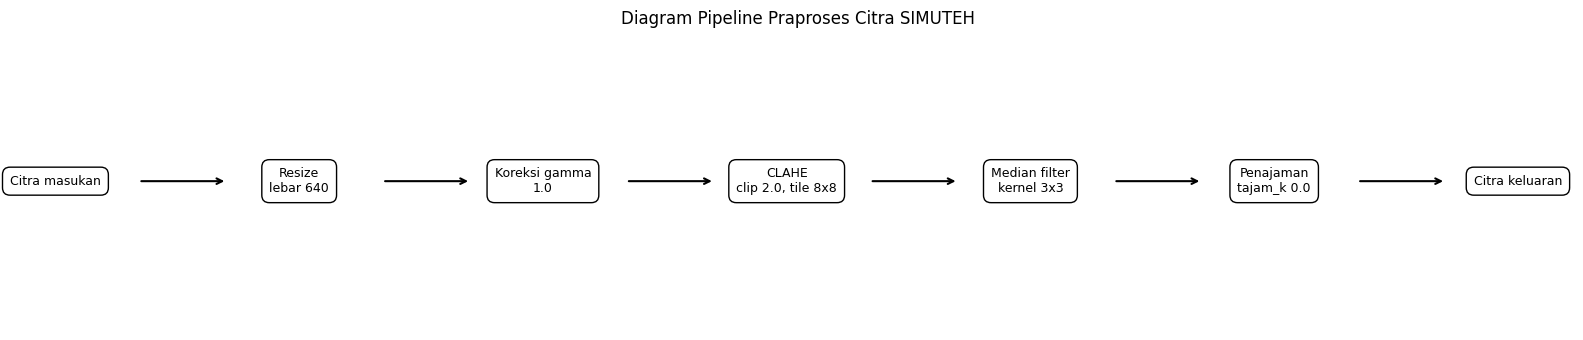

Tabel 13 disimpan: /content/drive/MyDrive/simuteh/hasil/b5_tabel13_justifikasi.csv
Diagram pipeline disimpan: /content/drive/MyDrive/simuteh/hasil/b5_diagram_pipeline.png


In [48]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

ROOT = Path("/content/drive/MyDrive/simuteh")
HASIL = ROOT / "hasil"

# Tabel 13: Justifikasi parameter praproses
data_tabel13 = [
    {
        "Tahap": "1. Resize",
        "Parameter akhir": "Lebar 640 piksel",
        "Bukti pendukung": "Petunjuk praktikum P5",
        "Risiko jika tidak tepat": "Ukuran tidak seragam dan detail bercak dapat hilang"
    },
    {
        "Tahap": "2. Koreksi gamma",
        "Parameter akhir": "Gamma 1.0",
        "Bukti pendukung": "Evaluasi KB B5 menunjukkan peningkatan pada 4 dari 5 kondisi, tetapi kondisi terang menurun",
        "Risiko jika tidak tepat": "Intensitas bercak dapat berubah dan KB dapat menurun"
    },
    {
        "Tahap": "3. CLAHE",
        "Parameter akhir": "clipLimit 2.0, tileGridSize 8x8",
        "Bukti pendukung": "Percobaan CLAHE pada B3",
        "Risiko jika tidak tepat": "Kontras berlebihan dapat memperjelas noise dan tekstur yang menyerupai bercak"
    },
    {
        "Tahap": "4. Penapisan",
        "Parameter akhir": "Median, kernel 3x3",
        "Bukti pendukung": "B4: median 5x5 memperoleh PSNR rata-rata 41.51 dB, tetapi kernel besar dapat mengurangi detail bercak",
        "Risiko jika tidak tepat": "Kernel besar dapat menghilangkan bercak kecil, sedangkan kernel kecil mungkin menyisakan noise"
    },
    {
        "Tahap": "5. Penajaman",
        "Parameter akhir": "tajam_k 0.0, penajaman dinonaktifkan",
        "Bukti pendukung": "Parameter awal P5 dan perlunya menghindari penajaman berlebihan",
        "Risiko jika tidak tepat": "Penajaman dapat memperkuat noise atau menghasilkan pola yang menyerupai bercak"
    }
]

df_tabel13 = pd.DataFrame(data_tabel13)

file_tabel13 = HASIL / "b5_tabel13_justifikasi.csv"
df_tabel13.to_csv(file_tabel13, index=False)

print("Tabel 13. Justifikasi Parameter Praproses")
display(df_tabel13)

# Diagram pipeline
tahapan = [
    "Citra masukan",
    "Resize\nlebar 640",
    "Koreksi gamma\n1.0",
    "CLAHE\nclip 2.0, tile 8x8",
    "Median filter\nkernel 3x3",
    "Penajaman\ntajam_k 0.0",
    "Citra keluaran"
]

fig, ax = plt.subplots(figsize=(16, 3.5))
ax.set_xlim(0, len(tahapan) * 2)
ax.set_ylim(0, 2)
ax.axis("off")

posisi = []

for i, tahap in enumerate(tahapan):
    x = 0.3 + i * 2.2
    posisi.append(x)

    ax.text(
        x, 1, tahap,
        ha="center", va="center", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="black")
    )

    if i < len(tahapan) - 1:
        ax.annotate(
            "",
            xy=(x + 1.55, 1),
            xytext=(x + 0.75, 1),
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )

plt.title("Diagram Pipeline Praproses Citra SIMUTEH")
plt.tight_layout()

file_pipeline = HASIL / "b5_diagram_pipeline.png"
plt.savefig(file_pipeline, dpi=200, bbox_inches="tight")
plt.show()

print("Tabel 13 disimpan:", file_tabel13)
print("Diagram pipeline disimpan:", file_pipeline)

In [49]:
from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/simuteh")
HASIL = ROOT / "hasil"

berkas_wajib = [
    "param_praproses.json",
    "b5_evaluasi_40_citra.csv",
    "b5_tabel12_kontras_bercak.csv",
    "b5_evaluasi_20_citra_sehat.csv",
    "b5_ringkasan_citra_sehat.csv",
    "b5_tabel13_justifikasi.csv",
    "b5_diagram_pipeline.png",
    "b5_panel_citra_sehat.png"
]

print("PEMERIKSAAN BERKAS B5")
print("=" * 45)

semua_ada = True

for nama in berkas_wajib:
    path = HASIL / nama
    status = "ADA" if path.exists() else "BELUM ADA"
    print(f"{status:12} {nama}")

    if not path.exists():
        semua_ada = False

if semua_ada:
    print("\nSemua berkas wajib pemeriksaan ditemukan.")

    with open(HASIL / "param_praproses.json", encoding="utf-8") as f:
        parameter = json.load(f)

    print("\nParameter praproses:")
    print(json.dumps(parameter, indent=2, ensure_ascii=False))

    evaluasi_bercak = pd.read_csv(
        HASIL / "b5_evaluasi_40_citra.csv"
    )
    evaluasi_sehat = pd.read_csv(
        HASIL / "b5_evaluasi_20_citra_sehat.csv"
    )

    print("\nJumlah citra berbercak:", len(evaluasi_bercak))
    print("Jumlah citra sehat:", len(evaluasi_sehat))
else:
    print("\nMasih ada berkas yang belum ditemukan.")

PEMERIKSAAN BERKAS B5
ADA          param_praproses.json
ADA          b5_evaluasi_40_citra.csv
ADA          b5_tabel12_kontras_bercak.csv
ADA          b5_evaluasi_20_citra_sehat.csv
ADA          b5_ringkasan_citra_sehat.csv
ADA          b5_tabel13_justifikasi.csv
ADA          b5_diagram_pipeline.png
ADA          b5_panel_citra_sehat.png

Semua berkas wajib pemeriksaan ditemukan.

Parameter praproses:
{
  "lebar": 640,
  "gamma": 1.0,
  "clahe_clip": 2.0,
  "clahe_tile": 8,
  "penapis": "median",
  "kernel": 3,
  "sigma": 1.0,
  "tajam_k": 0.0
}

Jumlah citra berbercak: 40
Jumlah citra sehat: 20


In [50]:
import json
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/simuteh")
DATA = ROOT / "data" / "sintetis"
HASIL = ROOT / "hasil"

# Baca data
label = pd.read_csv(DATA / "label.csv")
detail_bercak = pd.read_csv(HASIL / "b5_evaluasi_40_citra.csv")
detail_sehat = pd.read_csv(HASIL / "b5_evaluasi_20_citra_sehat.csv")
tabel12 = pd.read_csv(HASIL / "b5_tabel12_kontras_bercak.csv")
tabel13 = pd.read_csv(HASIL / "b5_tabel13_justifikasi.csv")

with open(HASIL / "param_praproses.json", encoding="utf-8") as f:
    parameter = json.load(f)

# 1. Periksa jumlah data
print("=== PEMERIKSAAN JUMLAH DATA ===")
print("Total dataset       :", len(label))
print("Citra sehat         :", (label["kelas"] == "sehat").sum())
print("Citra berbercak     :", label["kelas"].isin(["ringan", "berat"]).sum())
print("Evaluasi citra sehat:", len(detail_sehat))
print("Evaluasi berbercak  :", len(detail_bercak))

assert len(label) == 60
assert len(detail_sehat) == 20
assert len(detail_bercak) == 40

# 2. Periksa kondisi cahaya
print("\n=== PEMERIKSAAN KONDISI CAHAYA ===")
print("Distribusi dataset:")
print(label["kondisi_cahaya"].value_counts().sort_index())

print("\nDistribusi evaluasi berbercak:")
print(detail_bercak["kondisi_cahaya"].value_counts().sort_index())

print("\nDistribusi evaluasi sehat:")
print(detail_sehat["kondisi_cahaya"].value_counts().sort_index())

# 3. Periksa parameter
print("\n=== PARAMETER PRAPROSES ===")
print(json.dumps(parameter, indent=2, ensure_ascii=False))

# 4. Periksa nilai KB
print("\n=== TABEL 12 ===")
display(tabel12.round(4))

assert tabel12["kondisi_cahaya"].nunique() == 5
assert len(tabel12) == 5

# 5. Periksa kelengkapan Tabel 13
print("\n=== TABEL 13 ===")
display(tabel13)

assert len(tabel13) == 5

print("\nPemeriksaan dasar selesai.")

=== PEMERIKSAAN JUMLAH DATA ===
Total dataset       : 60
Citra sehat         : 20
Citra berbercak     : 40
Evaluasi citra sehat: 20
Evaluasi berbercak  : 40

=== PEMERIKSAAN KONDISI CAHAYA ===
Distribusi dataset:
kondisi_cahaya
bayangan          12
gelap             12
kontras_rendah    12
normal            12
terang            12
Name: count, dtype: int64

Distribusi evaluasi berbercak:
kondisi_cahaya
bayangan          8
gelap             8
kontras_rendah    8
normal            8
terang            8
Name: count, dtype: int64

Distribusi evaluasi sehat:
kondisi_cahaya
bayangan          4
gelap             4
kontras_rendah    4
normal            4
terang            4
Name: count, dtype: int64

=== PARAMETER PRAPROSES ===
{
  "lebar": 640,
  "gamma": 1.0,
  "clahe_clip": 2.0,
  "clahe_tile": 8,
  "penapis": "median",
  "kernel": 3,
  "sigma": 1.0,
  "tajam_k": 0.0
}

=== TABEL 12 ===


,kondisi_cahaya,jumlah_citra,KB_sebelum,KB_sesudah,perubahan_persen,catatan
0,bayangan,8,4.1400,6.9838,71.0328,Kontras bercak meningkat
1,gelap,8,9.1146,15.1451,65.2692,Kontras bercak meningkat
2,kontras_rendah,8,3.8967,4.8514,28.2274,Kontras bercak meningkat
3,normal,8,10.1787,11.9018,17.5586,Kontras bercak meningkat
4,terang,8,7.5888,6.1711,-19.1831,Kontras bercak menurun



=== TABEL 13 ===


,Tahap,Parameter akhir,Bukti pendukung,Risiko jika tidak tepat
0,1. Resize,Lebar 640 piksel,Petunjuk praktikum P5,Ukuran tidak seragam dan detail bercak dapat h...
1,2. Koreksi gamma,Gamma 1.0,Evaluasi KB B5 menunjukkan peningkatan pada 4 ...,Intensitas bercak dapat berubah dan KB dapat m...
2,3. CLAHE,"clipLimit 2.0, tileGridSize 8x8",Percobaan CLAHE pada B3,Kontras berlebihan dapat memperjelas noise dan...
3,4. Penapisan,"Median, kernel 3x3",B4: median 5x5 memperoleh PSNR rata-rata 41.51...,"Kernel besar dapat menghilangkan bercak kecil,..."
4,5. Penajaman,"tajam_k 0.0, penajaman dinonaktifkan",Parameter awal P5 dan perlunya menghindari pen...,Penajaman dapat memperkuat noise atau menghasi...



Pemeriksaan dasar selesai.


In [53]:
import json
from pathlib import Path

file_param = Path(
    "/content/drive/MyDrive/simuteh/hasil/param_praproses.json"
)

with open(file_param, "r", encoding="utf-8") as f:
    parameter = json.load(f)

print("KONFIGURASI PRAPROSES B5")
for nama, nilai in parameter.items():
    print(f"{nama}: {nilai}")

KONFIGURASI PRAPROSES B5
lebar: 640
gamma: 1.0
clahe_clip: 2.0
clahe_tile: 8
penapis: median
kernel: 3
sigma: 1.0
tajam_k: 0.0
